## D1 · Discrete probability

Probabilities of discrete outcomes (dice) using enumerated outcomes, tables and simulation.

In [966]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Every possible outcome of rolling three dice (6**3 = 216 rows)
df_combos = pd.read_csv("data/3_roll_combos.csv")

### The rules in code

#### Checking that probabilities sum to 1

**D1.01**

`Σ P(xi) = 1`

Adding up all the probabilities in a distribution allows us to check it is valid, since they must total 1. It is useful as a sanity check on any table of probabilities.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

For a fair die each of six outcomes has probability 1/6.

Watch out: sums of decimals carry a small rounding error, so compare with `np.isclose(sum(P), 1)` and not with `==`.

In [967]:
P = [1 / 6] * 6
print(f"P = {[round(p, 4) for p in P]}")

P = [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667]


In [968]:
print(f"total = {sum(P):.4f}")

total = 1.0000


In [969]:
print(f"is it 1? {np.isclose(sum(P), 1)}")

is it 1? True


In [970]:
f'The six probabilities add up to {sum(P):.4f}, so they form a valid distribution.' if np.isclose(sum(P), 1) else 'The probabilities do not add up to 1, so they are not a valid distribution.'

'The six probabilities add up to 1.0000, so they form a valid distribution.'

*See also:* Comparing decimals safely (D1) · Turning counts into probabilities (B4) · Adding a probability column (D1)

#### Adding probabilities for "or"

**D1.02**

`P(5 or 6) = P(5) + P(6)`

If outcomes cannot happen together, then adding their probabilities gives the probability that one of them occurs. It is useful for "or" questions about separate outcomes. Alternatively, count the favourable outcomes in the table and divide by the total.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

Two outcomes of one roll cannot happen together (they are mutually exclusive), so their probabilities add.

In [971]:
p5 = 1 / 6          # P(5)
p6 = 1 / 6          # P(6)
print(f"P(5) = {p5:.4f}, P(6) = {p6:.4f}")

P(5) = 0.1667, P(6) = 0.1667


In [972]:
print(f"P(5 or 6) = {p5 + p6:.4f}")

P(5 or 6) = 0.3333


Check by counting the favourable outcomes of one die:

In [973]:
faces = [1, 2, 3, 4, 5, 6]
p_count = sum(1 for f in faces if f in (5, 6)) / len(faces)
print(f"counting gives {p_count:.4f}")

counting gives 0.3333


In [974]:
f'Adding gives {p5 + p6:.4f} and counting gives {p_count:.4f}, so the two methods ' + ('agree.' if np.isclose(p5 + p6, p_count) else 'disagree.')

'Adding gives 0.3333 and counting gives 0.3333, so the two methods agree.'

*See also:* Favourable outcomes over total outcomes (D1) · Multiplying probabilities for "and" (D1) · Counting combined events (D1)

#### Multiplying probabilities for "and"

**D1.03**

`P(A and B) = P(A) · P(B)`

If events are independent, then multiplying their probabilities gives the chance that both happen. It is useful for any run of independent trials. Alternatively, count outcomes in the full table of combinations.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [975]:
p_six = 1 / 6
print(f"P(two sixes in a row) = {p_six * p_six:.4f}")

P(two sixes in a row) = 0.0278


In [976]:
print(f"P(three sixes)        = {p_six ** 3:.5f}")

P(three sixes)        = 0.00463


Check with the table of all 216 outcomes:

In [977]:
mask_all_sixes = (df_combos[["roll_1", "roll_2", "roll_3"]] == 6).all(axis=1)
print(f"{mask_all_sixes.sum()} / {len(df_combos)} = {mask_all_sixes.mean():.5f}")

1 / 216 = 0.00463


In [978]:
f'Multiplying gives P(three sixes) = {p_six ** 3:.5f}. Counting the table gives {mask_all_sixes.mean():.5f}, so the two methods ' + ('agree.' if np.isclose(p_six ** 3, mask_all_sixes.mean()) else 'disagree.')

'Multiplying gives P(three sixes) = 0.00463. Counting the table gives 0.00463, so the two methods agree.'

*See also:* Counting combined events (D1) · Adding probabilities for "or" (D1)

#### The complement rule

**D1.04**

`P(X ≥ k) = 1 − P(X ≤ k − 1)`

If we want the probability of "at least" or "not A", then the complement rule `P(not A) = 1 − P(A)` finds it from the opposite event. It is useful when the opposite event is simpler to count. Alternatively, count the favourable outcomes directly.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [979]:
# display the example data
df_combos.head()

,roll_1,roll_2,roll_3,total
0,1,1,1,3
1,1,1,2,4
2,1,1,3,5
3,1,1,4,6
4,1,1,5,7


In [980]:
p_le_11 = (df_combos["total"] <= 11).mean()      # True counts as 1 and False as 0, so the mean is the proportion of True
print(f"P(total <= 11) = {p_le_11:.4f}")

P(total <= 11) = 0.6250


In [981]:
print(f"1 - that       = {1 - p_le_11:.4f}")

1 - that       = 0.3750


In [982]:
print(f"direct count   = {(df_combos['total'] >= 12).mean():.4f}")

direct count   = 0.3750


In [983]:
print(f"The complement rule gives P(total >= 12) = {1 - p_le_11:.4f}, the same as counting those outcomes directly ({(df_combos['total'] >= 12).mean():.4f}).")

The complement rule gives P(total >= 12) = 0.3750, the same as counting those outcomes directly (0.3750).


*See also:* Favourable outcomes over total outcomes (D1) · Adding a cumulative probability column (D1) · Range probabilities (D1)

#### Expected value

**D1.05**

`E(X) = Σ P(xi) · xi`

If we have each outcome and its probability, then multiplying each outcome by its probability and adding gives the expected value, `E(X) = Σ P(xi)·xi`. It is useful for the long-run average of a random quantity. Alternatively, simulate many trials and take the mean.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

The expected value of one fair die:

In [984]:
faces = np.arange(1, 7)
prob = np.full(6, 1 / 6)
print(f"faces        = {faces.tolist()}")

faces        = [1, 2, 3, 4, 5, 6]


In [985]:
print(f"probabilities = {prob.round(3).tolist()}")

probabilities = [0.167, 0.167, 0.167, 0.167, 0.167, 0.167]


In [986]:
expected = (prob * faces).sum()
print(f"E(X) = {expected:.2f}")

E(X) = 3.50


In [987]:
print(f"The expected value of one roll is {expected:.1f}. This is the long-run average, and it is not a value that a single roll can take.")

The expected value of one roll is 3.5. This is the long-run average, and it is not a value that a single roll can take.


*See also:* Expectation from a table (D1) · Simulating many dice rolls (D1) · Variance (D1)

### Plotting a distribution

#### Plotting a probability distribution

**D1.06**

`plt.bar(events, P_events, width=0.6)`

If we have the outcomes and their probabilities, then a bar plot shows the shape of a discrete distribution. It is useful for comparing distributions and spotting symmetry. Alternatively, `sns.barplot` on a table with a probability column does the same.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

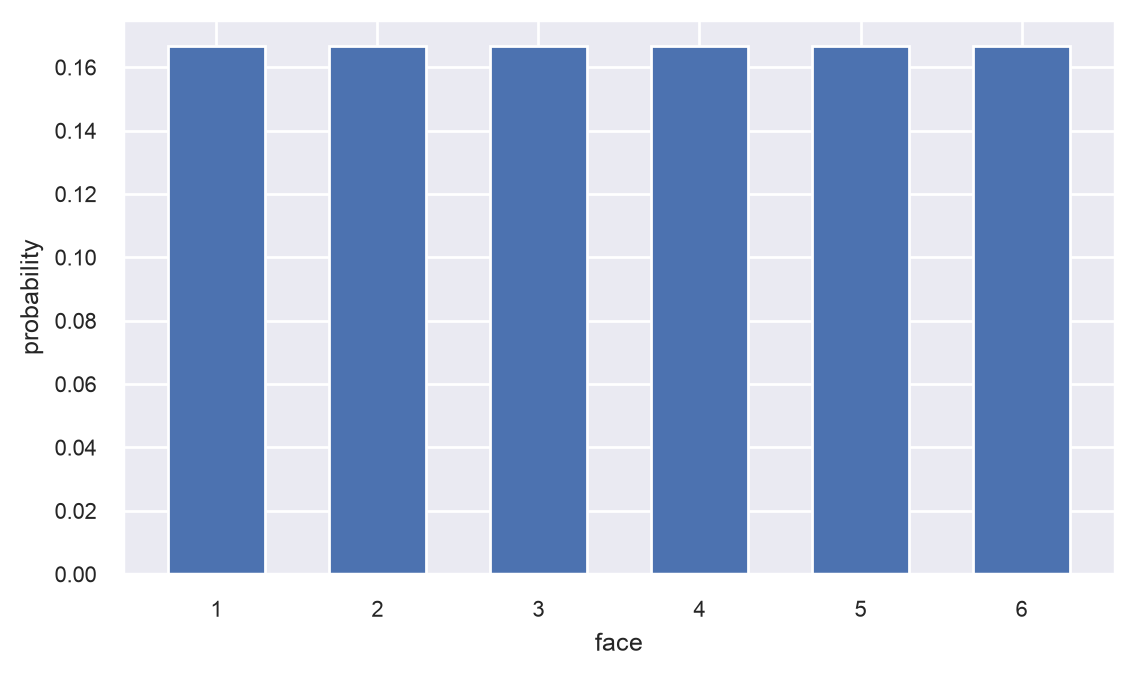

In [988]:
faces = np.arange(1, 7)
prob = np.full(6, 1 / 6)
plt.bar(faces, prob, width=0.6)
plt.xlabel("face")
plt.ylabel("probability");

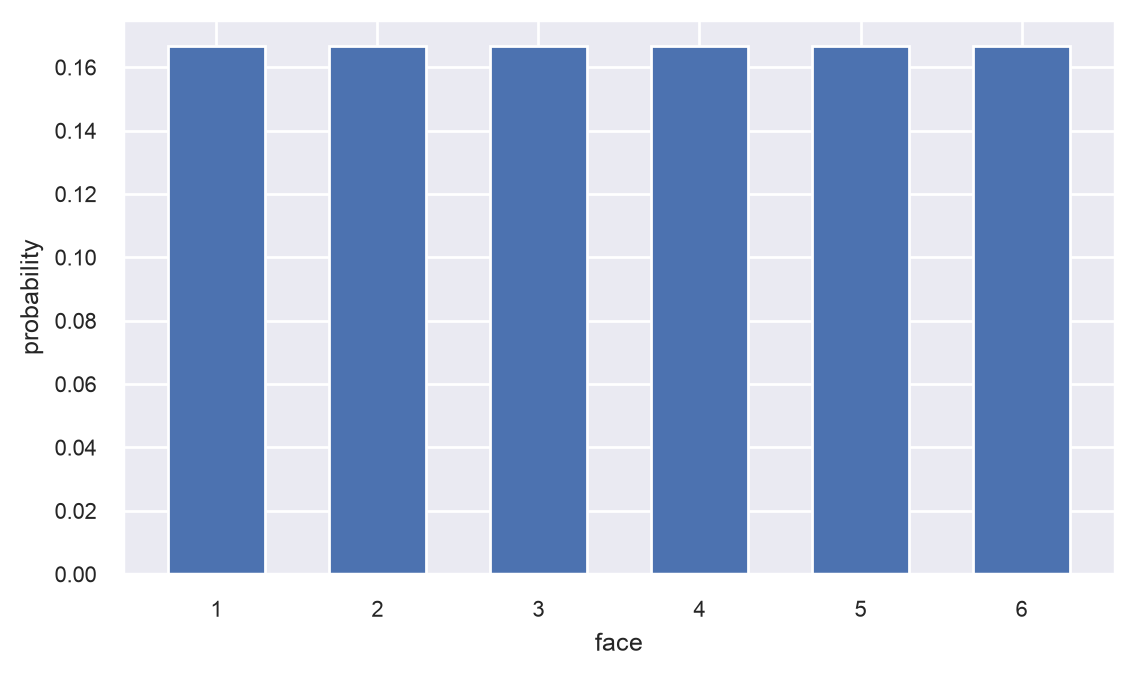

In [989]:
# the same plot in object-oriented style (ax. methods)
faces = np.arange(1, 7)
prob = np.full(6, 1 / 6)
fig, ax = plt.subplots()
ax.bar(faces, prob, width=0.6)
ax.set_xlabel("face")
ax.set_ylabel("probability");

*See also:* Drawing a bar plot of values (C3) · Drawing a probability bar plot (C2) · Plotting a cumulative distribution (D1)

#### Plotting a cumulative distribution

**D1.07**

`plt.bar(x, np.cumsum(P))`

If we have the probabilities of each outcome, then plotting their running total shows `P(X ≤ x)` at a glance. It is useful for reading percentiles. Alternatively, `sns.ecdfplot` draws the same thing from raw data.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

[0.167 0.333 0.5   0.667 0.833 1.   ]


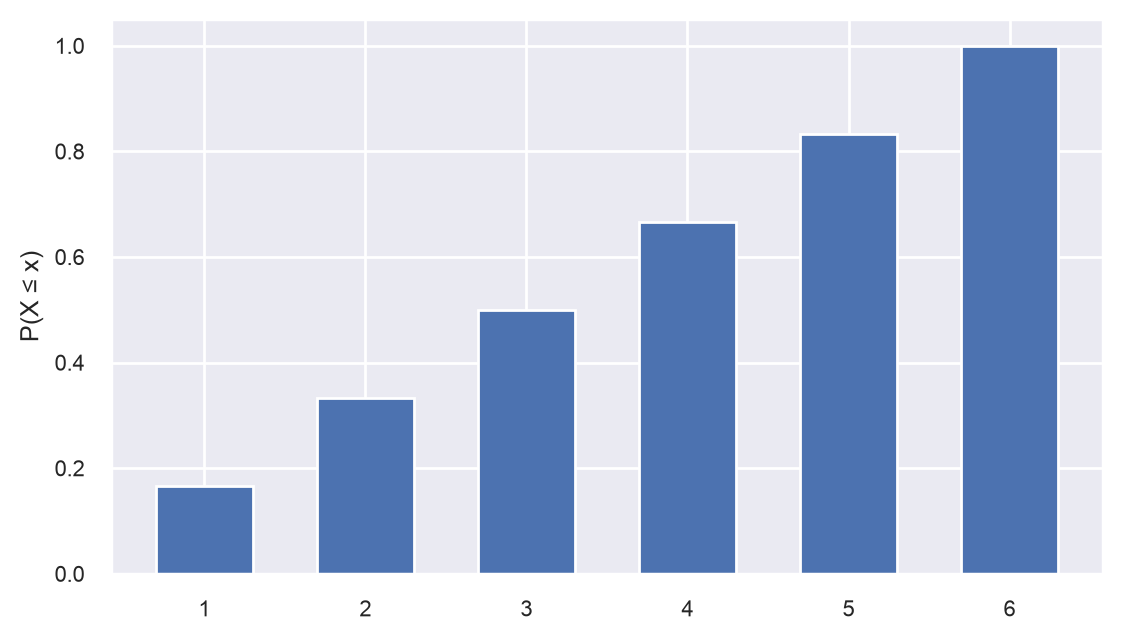

In [990]:
faces = np.arange(1, 7)
prob = np.full(6, 1 / 6)
print(np.cumsum(prob).round(3))
plt.bar(faces, np.cumsum(prob), width=0.6)
plt.ylabel("P(X ≤ x)");

[0.167 0.333 0.5   0.667 0.833 1.   ]


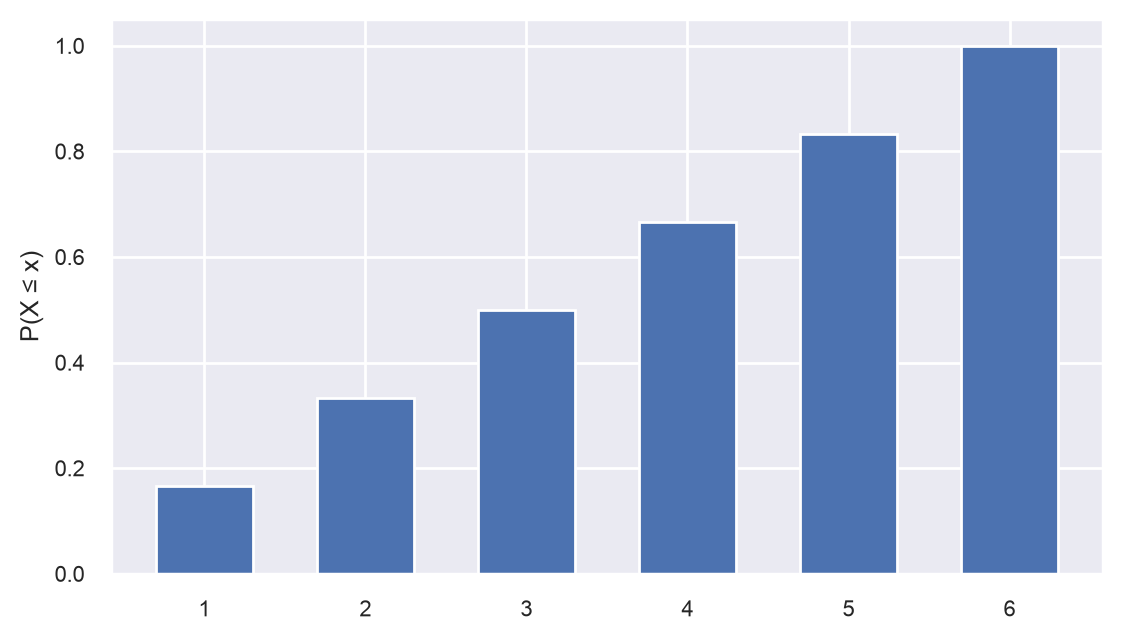

In [991]:
# the same plot in object-oriented style (ax. methods)
faces = np.arange(1, 7)
prob = np.full(6, 1 / 6)
print(np.cumsum(prob).round(3))
fig, ax = plt.subplots()
ax.bar(faces, np.cumsum(prob), width=0.6)
ax.set_ylabel("P(X ≤ x)");

*See also:* Drawing a cumulative distribution with `ecdfplot` (C3) · Calculating cumulative sums (B4) · Adding a cumulative probability column (D1)

### Probability from enumerated outcomes

#### Favourable outcomes over total outcomes

**D1.08**

`mask = df['col'] == value; len(df[mask]) / len(df)`

If all outcomes are equally likely and we have a table listing every one, then the probability of an event is the number of favourable rows divided by the total. It is useful whenever the outcomes can be enumerated. Alternatively, `mask.mean()` gives the same proportion in one step.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [992]:
# display the example data
df_combos.head()

,roll_1,roll_2,roll_3,total
0,1,1,1,3
1,1,1,2,4
2,1,1,3,5
3,1,1,4,6
4,1,1,5,7


In [993]:
mask = df_combos["roll_1"] == 6
print(f"{len(df_combos[mask])} of {len(df_combos)} outcomes have a 6 on the first die")

36 of 216 outcomes have a 6 on the first die


In [994]:
print(f"favourable / total = {len(df_combos[mask]) / len(df_combos):.4f}")

favourable / total = 0.1667


In [995]:
print(f"mask.mean()        = {mask.mean():.4f}")      # same answer: True counts as 1 and False as 0, so the mean is the proportion of True

mask.mean()        = 0.1667


In [996]:
print(f"The probability of a 6 on the first die is {mask.mean():.4f} ({mask.sum()}/{len(df_combos)}), which equals 1/6 = {1 / 6:.4f}.")

The probability of a 6 on the first die is 0.1667 (36/216), which equals 1/6 = 0.1667.


*See also:* Building a mask (B3) · Counting combined events (D1) · Building a frequency table (D1)

#### Counting combined events

**D1.09**

`(df['col_1'] <= a) & (df['col_2'] <= b)`

If an event needs several conditions to hold at once, then combining masks with `&` or `|` counts the outcomes that satisfy them. It is useful for "and" / "or" events across different dice. Alternatively, multiply probabilities when the events are independent.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [997]:
mask_both = (df_combos["roll_1"] <= 3) & (df_combos["roll_2"] <= 3)
print(f"{mask_both.sum()} / {len(df_combos)} = {mask_both.mean():.4f}")

54 / 216 = 0.2500


In [998]:
print(f"check by multiplying: {0.5 * 0.5:.4f}")

check by multiplying: 0.2500


In [999]:
print(f"{mask_both.sum()} of {len(df_combos)} outcomes have both of the first two dice at 3 or below ({mask_both.mean():.4f}), matching 0.5 × 0.5 because the dice are independent.")

54 of 216 outcomes have both of the first two dice at 3 or below (0.2500), matching 0.5 × 0.5 because the dice are independent.


*See also:* Combining conditions with `&` and `|` (B3) · Multiplying probabilities for "and" (D1) · Building a mask (B3)

#### Building a frequency table

**D1.10**

`df['col'].value_counts().to_frame().sort_values(by='col')`

If we have a table of every outcome, then counting each total gives a frequency table, the first step to a probability distribution. It is useful for seeing how often each result occurs. Alternatively, `pd.crosstab` or `groupby().size()` give the same counts.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1000]:
# display the example data
df_combos["total"].head()

0    3
1    4
2    5
3    6
4    7
Name: total, dtype: int64

In [1001]:
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals.head()

,count
total,
3,1
4,3
5,6
6,10
7,15


*See also:* Counting two categories together (B5) · Counting each category (B5) · Chaining methods on one line (B4)

#### Adding a probability column

**D1.11**

`df['prob'] = df['count'] / total`

If we have a column of counts, then dividing by 6³ adds a column of probabilities. It is useful for a full probability distribution table. Alternatively, `value_counts(normalize=True)` gives probabilities directly.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1002]:
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals.head(3)                       # before: counts only

,count
total,
3,1
4,3
5,6


In [1003]:
df_totals["prob"] = df_totals["count"] / 6 ** 3
df_totals.head(3)                       # after: a probability column

,count,prob
total,,
3,1,0.004630
4,3,0.013889
5,6,0.027778


*See also:* Counting each category (B5) · Turning counts into probabilities (B4)

#### Expectation from a table

**D1.12**

`(df['prob'] * df['value']).sum()`

If we have a table with a probability column and an outcome column, then multiplying them and summing gives the expected value. It is useful when the distribution is known but not the raw rolls. Alternatively, `mean()` of the raw outcomes gives the same answer.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1004]:
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals["prob"] = df_totals["count"] / 6 ** 3
df_t = df_totals.reset_index()
df_t.head(3)

,total,count,prob
0,3,1,0.004630
1,4,3,0.013889
2,5,6,0.027778


In [1005]:
print(f"from the table: {(df_t['prob'] * df_t['total']).sum():.2f}")

from the table: 10.50


In [1006]:
print(f"by averaging  : {df_combos['total'].mean():.2f}")       # same answer

by averaging  : 10.50


In [1007]:
print(f"The expected total of three dice is {(df_t['prob'] * df_t['total']).sum():.1f}, which is three times the expected value of one die (3.5).")

The expected total of three dice is 10.5, which is three times the expected value of one die (3.5).


*See also:* Expected value (D1) · Adding a probability column (D1) · Variance (D1)

#### Adding a cumulative probability column

**D1.13**

`df['cum_prob'] = df['prob'].cumsum()`

If we have a column of probabilities in order, then `.cumsum()` adds a column of `P(X ≤ x)`. It is useful for "at most" and "at least" questions and for ranges. Alternatively, sum a masked column: `prob[total <= x].sum()`.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1008]:
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals["prob"] = df_totals["count"] / 6 ** 3
df_totals.loc[8:12]                     # before: probabilities

,count,prob
total,,
8,21,0.097222
9,25,0.115741
10,27,0.125000
11,27,0.125000
12,25,0.115741


In [1009]:
df_totals["cum_prob"] = df_totals["prob"].cumsum()
df_totals.loc[8:12]                     # after: running total added

,count,prob,cum_prob
total,,,
8,21,0.097222,0.259259
9,25,0.115741,0.375000
10,27,0.125000,0.500000
11,27,0.125000,0.625000
12,25,0.115741,0.740741


*See also:* Calculating cumulative sums (B4) · The complement rule (D1) · Range probabilities (D1)

#### Range probabilities

**D1.14**

`P(a < X ≤ b) = P(X ≤ b) − P(X ≤ a)`

If we have a cumulative probability column, then subtracting two of its values gives the probability of a range, `P(a < X ≤ b) = P(X ≤ b) − P(X ≤ a)`. It is useful for "between" questions. Alternatively, `.between()` on the raw outcomes gives the same.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1010]:
df_totals = df_combos["total"].value_counts().to_frame().sort_values(by="total")
df_totals["cum_prob"] = (df_totals["count"] / 216).cumsum()
col_cum = df_totals["cum_prob"]
print(f"P(9 < X <= 12) = {col_cum.loc[12] - col_cum.loc[9]:.4f}")

P(9 < X <= 12) = 0.3657


In [1011]:
print(f"check          = {df_combos['total'].between(10, 12).mean():.4f}")

check          = 0.3657


In [1012]:
p_range = col_cum.loc[12] - col_cum.loc[9]
p_count = df_combos["total"].between(10, 12).mean()
f'P(9 < X <= 12) is {p_range:.4f} from the cumulative column and {p_count:.4f} from counting the outcomes, so the two methods ' + ('agree.' if np.isclose(p_range, p_count) else 'disagree.')

'P(9 < X <= 12) is 0.3657 from the cumulative column and 0.3657 from counting the outcomes, so the two methods agree.'

*See also:* Filtering with `~`, `isin()` and `between()` (B3) · Adding a cumulative probability column (D1) · The complement rule (D1)

### Simulation and other tools

#### Simulating random draws

**D1.15**

`np.random.choice(outcomes, size, p=None)`

***(non-examinable)***

The `np.random.choice()` function allows us to simulate random draws from any list of outcomes: die faces, `"H"` and `"T"`, colours of balls in a bag. It is useful for acting out a probability experiment on the computer. Alternatively, `np.random.randint(1, 7)` is a shortcut for fair dice, and `rng.choice()` is the newer-generator version.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

Give the list of possible outcomes and how many draws are needed. Each draw is independent and, by default, every outcome is equally likely.

In [1013]:
np.random.seed(1)                          # fixed seed, so the output is repeatable

In [1014]:
faces = [1, 2, 3, 4, 5, 6]
np.random.choice(faces, size=10)              # ten rolls of a fair die

array([6, 4, 5, 1, 2, 4, 6, 1, 1, 2])

In [1015]:
np.random.choice(["H", "T"], size=10)         # ten coin tosses

array(['H', 'T', 'T', 'H', 'H', 'T', 'H', 'H', 'H', 'T'], dtype='<U1')

Outcomes can be anything, and `p=` gives each outcome its own probability (they must add to 1):

In [1016]:
np.random.choice(["red", "blue", "green"], size=8, p=[0.5, 0.3, 0.2])

array(['blue', 'red', 'green', 'red', 'blue', 'red', 'blue', 'red'],
      dtype='<U5')

`replace=False` draws without putting items back, as when dealing cards:

In [1017]:
np.random.choice([1, 2, 3, 4, 5], size=3, replace=False)

array([5, 4, 2])

*See also:* Choosing random items from a list (A4) · Drawing random integers (A4) · Simulating many draws and comparing with the theory (D1)

#### Simulating many draws and comparing with the theory

**D1.16**

`pd.Series(draws).value_counts(normalize=True)`

***(non-examinable)***

If we can draw random outcomes, then counting many of them estimates the probabilities by experiment. It is useful for checking an exact answer or for problems that are hard to enumerate. Alternatively, calculate the exact probability from the table of all outcomes.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

The more draws, the closer the proportions get to the true probabilities.

In [1018]:
np.random.seed(1)                          # fixed seed, so the output is repeatable

In [1019]:
draws = np.random.choice(["H", "T"], size=1000, p=[0.7, 0.3])     # a biased coin
draws[:10].tolist()

['H', 'T', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']

In [1020]:
pd.Series(draws).value_counts(normalize=True)      # observed proportions: should be near 0.7 / 0.3

H    0.703
T    0.297
Name: proportion, dtype: float64

In [1021]:
faces = np.random.choice([1, 2, 3, 4, 5, 6], size=6000)
pd.Series(faces).value_counts(normalize=True).sort_index().round(3)    # each near 1/6 = 0.167

1    0.162
2    0.162
3    0.164
4    0.169
5    0.166
6    0.177
Name: proportion, dtype: float64

In [1022]:
props = pd.Series(faces).value_counts(normalize=True)
print(f"With {len(faces):,} simulated rolls, every face is within {(props - 1 / 6).abs().max():.3f} of the theoretical probability 1/6 = {1 / 6:.3f}.")

With 6,000 simulated rolls, every face is within 0.011 of the theoretical probability 1/6 = 0.167.


*See also:* Simulating random draws (D1) · Counting proportions instead of numbers (B5) · Favourable outcomes over total outcomes (D1)

#### Simulating many dice rolls

**D1.17**

`np.random.randint(low, high, size=(rows, cols)).sum(axis=1)`

***(non-examinable)***

If we simulate thousands of throws of three dice, then the proportion of throws meeting a condition estimates its probability. It is useful for checking exact answers or for problems too hard to enumerate. Alternatively, enumerate every outcome (as above) when the number is small.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1023]:
np.random.seed(1)                          # fixed seed, so the output is repeatable

In [1024]:
rolls = np.random.randint(1, 7, size=(10000, 3))     # 10,000 throws of three dice
rolls[:3].tolist()

[[6, 4, 5], [1, 2, 4], [6, 1, 1]]

In [1025]:
totals = rolls.sum(axis=1)
p_sim = (totals >= 15).mean()
p_exact = (df_combos["total"] >= 15).mean()
print(f"simulated P(total >= 15) = {p_sim:.4f}")

simulated P(total >= 15) = 0.0937


In [1026]:
print(f"exact     P(total >= 15) = {p_exact:.4f}")

exact     P(total >= 15) = 0.0926


In [1027]:
print(f"The simulated probability ({p_sim:.4f}) is within {abs(p_sim - p_exact):.4f} of the exact value ({p_exact:.4f}); more throws would bring it closer.")

The simulated probability (0.0937) is within 0.0011 of the exact value (0.0926); more throws would bring it closer.


*See also:* Simulating random draws (D1) · The complement rule (D1) · Simulating many draws and comparing with the theory (D1)

#### Binomial probabilities

**D1.18**

`binom.pmf(k, n, p), binom.cdf(k, n, p)`

***(non-examinable)***

The `binom.pmf()` and `binom.cdf()` functions allow us to calculate the probability of a given number of successes in n independent trials. They are useful for coin tosses or any yes/no repeated trial. Alternatively, `math.comb` counts the outcomes directly, and the probabilities follow from them.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1028]:
from scipy.stats import binom

In [1029]:
n, p = 3, 0.5               # 3 coin tosses
for k in range(4):
    print(f"P({k} heads) = {binom.pmf(k, n, p):.3f}")
print(f"P(at most 2 heads) = {binom.cdf(2, n, p):.3f}")

P(0 heads) = 0.125
P(1 heads) = 0.375
P(2 heads) = 0.375
P(3 heads) = 0.125
P(at most 2 heads) = 0.875


*See also:* Counting combinations (D1) · Simulating random draws (D1) · P(X ≤ x) with the CDF (D2)

#### Counting combinations

**D1.19**

`math.comb(n, k)`

***(non-examinable)***

The `math.comb(n, k)` function allows us to count the ways to choose k items from n. It is useful for counting arrangements in probability problems. Alternatively, `scipy.special.comb` works on arrays.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1030]:
import math

In [1031]:
math.comb(5, 2)              # ways to choose 2 from 5

10

In [1032]:
math.comb(3, 2) * 0.5 ** 3   # P(exactly 2 heads in 3 tosses)

0.375

*See also:* Binomial probabilities (D1) · Simulating many draws and comparing with the theory (D1) · Variance (D1) · Counting combined events (D1)

#### Variance

**D1.20**

`Var(X) = Σ P(xi)(xi − μ)²`

***(non-examinable)***

If we have a probability distribution, then weighting the squared distances from the mean by their probabilities gives the variance, `Σ P(xi)(xi − μ)²`. It is useful for measuring how spread out a distribution is. Alternatively, simulate and take `.var()`.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1033]:
faces = np.arange(1, 7)
prob = np.full(6, 1 / 6)
mu = (prob * faces).sum()
variance = ((faces - mu) ** 2 * prob).sum()
print(f"mean     = {mu:.2f}")

mean     = 3.50


In [1034]:
print(f"variance = {variance:.4f}")

variance = 2.9167


*See also:* Calculating variance, mode and standard error (B5) · Expected value (D1) · Expectation from a table (D1)

#### Comparing decimals safely

**D1.21**

`np.isclose(a, b)`

***(non-examinable)***

The `np.isclose(a, b)` function allows us to test whether two decimals are equal within rounding error. It is useful because numbers like 1/6 or 0.1 are stored approximately, so `==` can fail. Alternatively, `round(a, 8) == round(b, 8)` also works.

**Context.** The examples use dice. A fair die has six equally likely faces, and the table of three dice lists all 216 possible outcomes of three rolls.

In [1035]:
0.1 + 0.2 == 0.3               # False

False

In [1036]:
0.1 + 0.2

0.30000000000000004

In [1037]:
np.isclose(0.1 + 0.2, 0.3)     # True

np.True_

*See also:* Checking that probabilities sum to 1 (D1) · Simulating random draws (D1) · Comparing values (A2)